<a href="https://colab.research.google.com/github/Calon-raja-ngoding/PCVK_Ganjil_2026/blob/main/Pertemuan7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

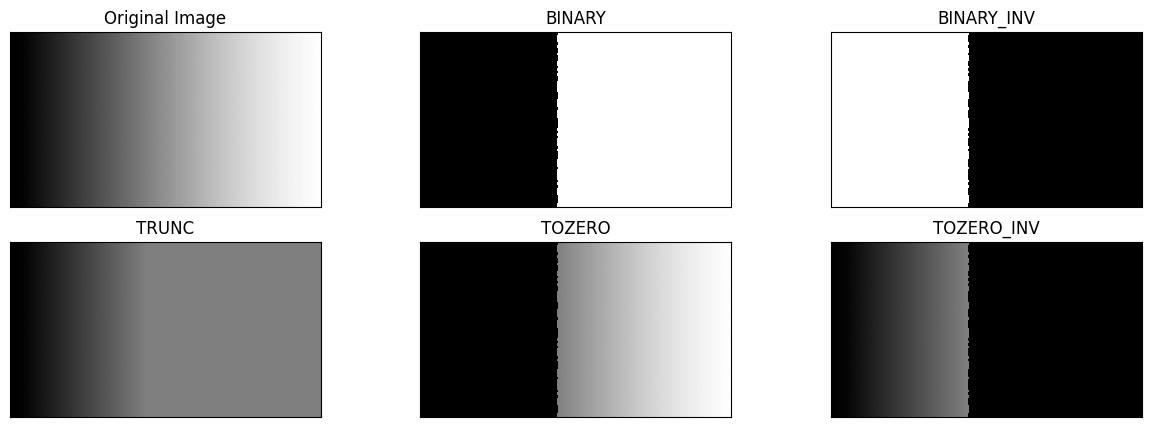

In [9]:
filepath = ('/content/drive/MyDrive/PCVK/gradient.jpg')
img = cv.imread(filepath)
thresh = 127
maxvel = 255

#1. threshold binary jika pixel di img . 127
ret, thresh1 = cv.threshold(img, thresh, maxvel, cv.THRESH_BINARY)
#2. threshold binary inverse jika pixel > thresh
ret, thresh2 = cv.threshold(img, thresh, maxvel, cv.THRESH_BINARY_INV)
#3. threshold truncate jika pixel > thresh
ret, thresh3 = cv.threshold(img, thresh, maxvel, cv.THRESH_TRUNC)
#4. threshold Tozero jika pixel > thresh
ret, thresh4 = cv.threshold(img, thresh, maxvel, cv.THRESH_TOZERO)
#5. threshold Tozero inverse jika pixel > thresh
ret, thresh5 = cv.threshold(img, thresh, maxvel, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
  plt.subplot(2, 3, i+1), plt.imshow(images[i], 'gray', interpolation = 'nearest')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

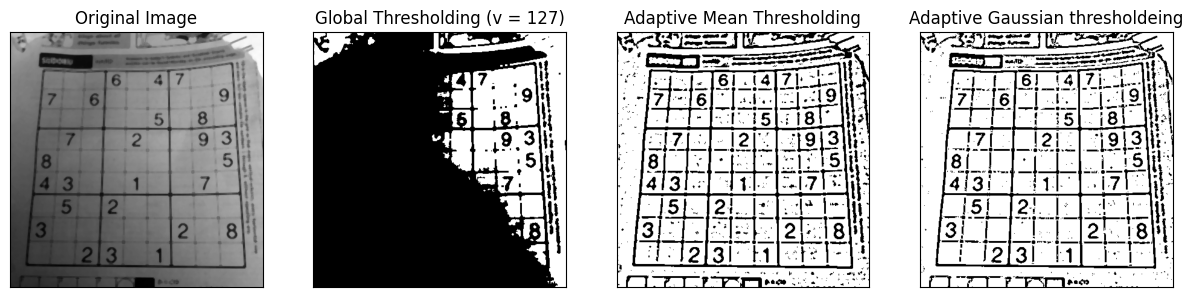

In [10]:
filepath = ('/content/drive/MyDrive/PCVK/sudoku-original.jpg')
citra = cv.medianBlur(cv.imread(filepath), 5)
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

thresh = 127

ret, th1 = cv.threshold(gray, thresh, 255, cv.THRESH_BINARY)
th2 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 11, 2)
th3 = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

titles = ['Original Image', 'Global Thresholding (v = 127)', 'Adaptive Mean Thresholding', 'Adaptive Gaussian thresholdeing']
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(15, 5))
for i in range(len(citra2)):
  plt.subplot(1, 4, i+1), plt.imshow(citra2[i], 'gray')
  plt.title(titles[i])
  plt.xticks([]), plt.yticks([])
plt.show()

/tmp/ipykernel_33439/2726839121.py:20: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
/tmp/ipykernel_33439/2726839121.py:21: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


93


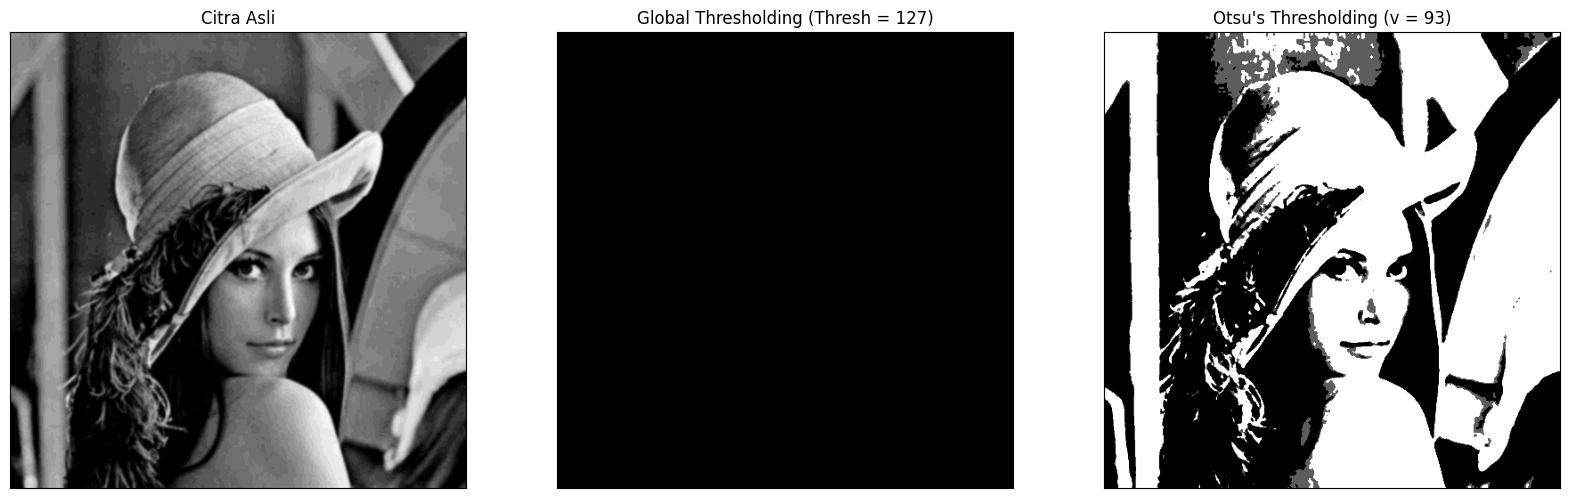

In [11]:
filename = ('/content/drive/MyDrive/PCVK/lena_gs_lc2.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh = 127

def otsu(gray):
  pixel_number = gray.shape[0] * gray.shape[1]
  mean_weight = 1.0/pixel_number
  his, bins = np.histogram(gray, np.arange(0,257))
  final_thresh = -1
  final_value = -1
  intensity_arr = np.arange(256)

  for t in bins[1:-1]:
    pcb = np.sum(his[:t])
    pcf = np.sum(his[t:])
    Wb = pcb * mean_weight
    Wf = pcf * mean_weight

    mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
    muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)

    value = Wb * Wf * (mub - muf) ** 2

    if value > final_value:
      final_thresh = t
      final_value = value

  final_img = gray.copy()
  print(final_thresh)
  final_img[gray > final_thresh] = 255
  final_img[gray < final_thresh] = 0
  return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)

x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))

for i in range(len(citra3)):
  plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
  plt.title(titles[i])
  plt.xticks([]),plt.yticks([])

plt.show()

Nilai Pixel Minimum : 85
Nilai Pixel Maximum : 108
Nilai Rata-rata Pixel : 93.23


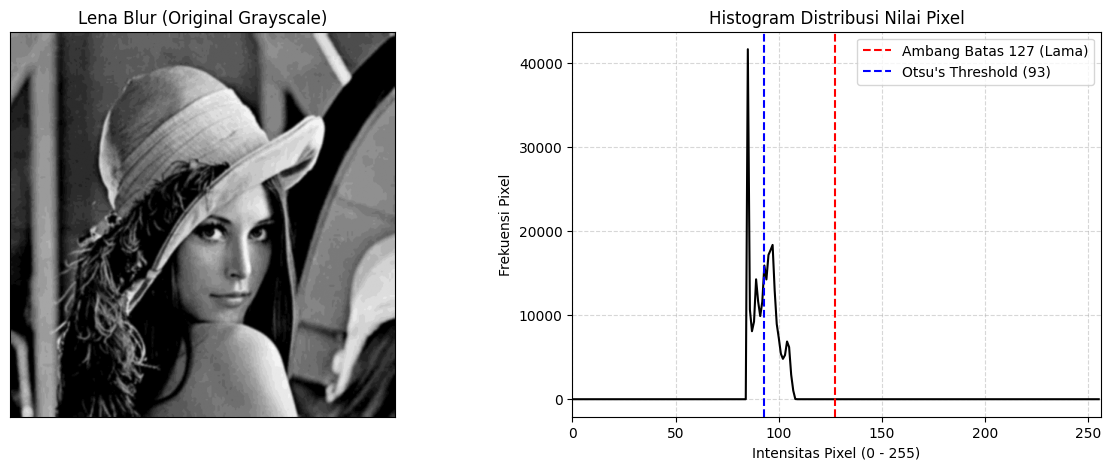

In [12]:
filepath = '/content/drive/MyDrive/PCVK/lena_gs_lc2.jpg'
img = cv.imread(filepath, 0)
blur = cv.GaussianBlur(img, (5,5), 0)

min_val = np.min(blur)
max_val = np.max(blur)
mean_val = np.mean(blur)

print(f"Nilai Pixel Minimum : {min_val}")
print(f"Nilai Pixel Maximum : {max_val}")
print(f"Nilai Rata-rata Pixel : {mean_val:.2f}")

hist = cv.calcHist([blur], [0], None, [256], [0, 256])

plt.figure(figsize = (15, 5))

plt.subplot(1, 2, 1)
plt.imshow(blur, cmap = 'gray')
plt.title('Lena Blur (Original Grayscale)')
plt.xticks([]), plt.yticks([])

plt.subplot(1, 2, 2)
plt.plot(hist, color = 'black')
plt.axvline(x = 127, color = 'red', linestyle = '--', label = 'Ambang Batas 127 (Lama)')
plt.axvline(x = 93, color = 'blue', linestyle = '--', label = "Otsu's Threshold (93)")
plt.title('Histogram Distribusi Nilai Pixel')
plt.xlabel('Intensitas Pixel (0 - 255)')
plt.ylabel('Frekuensi Pixel')
plt.xlim([0, 256])
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.5)

plt.show()

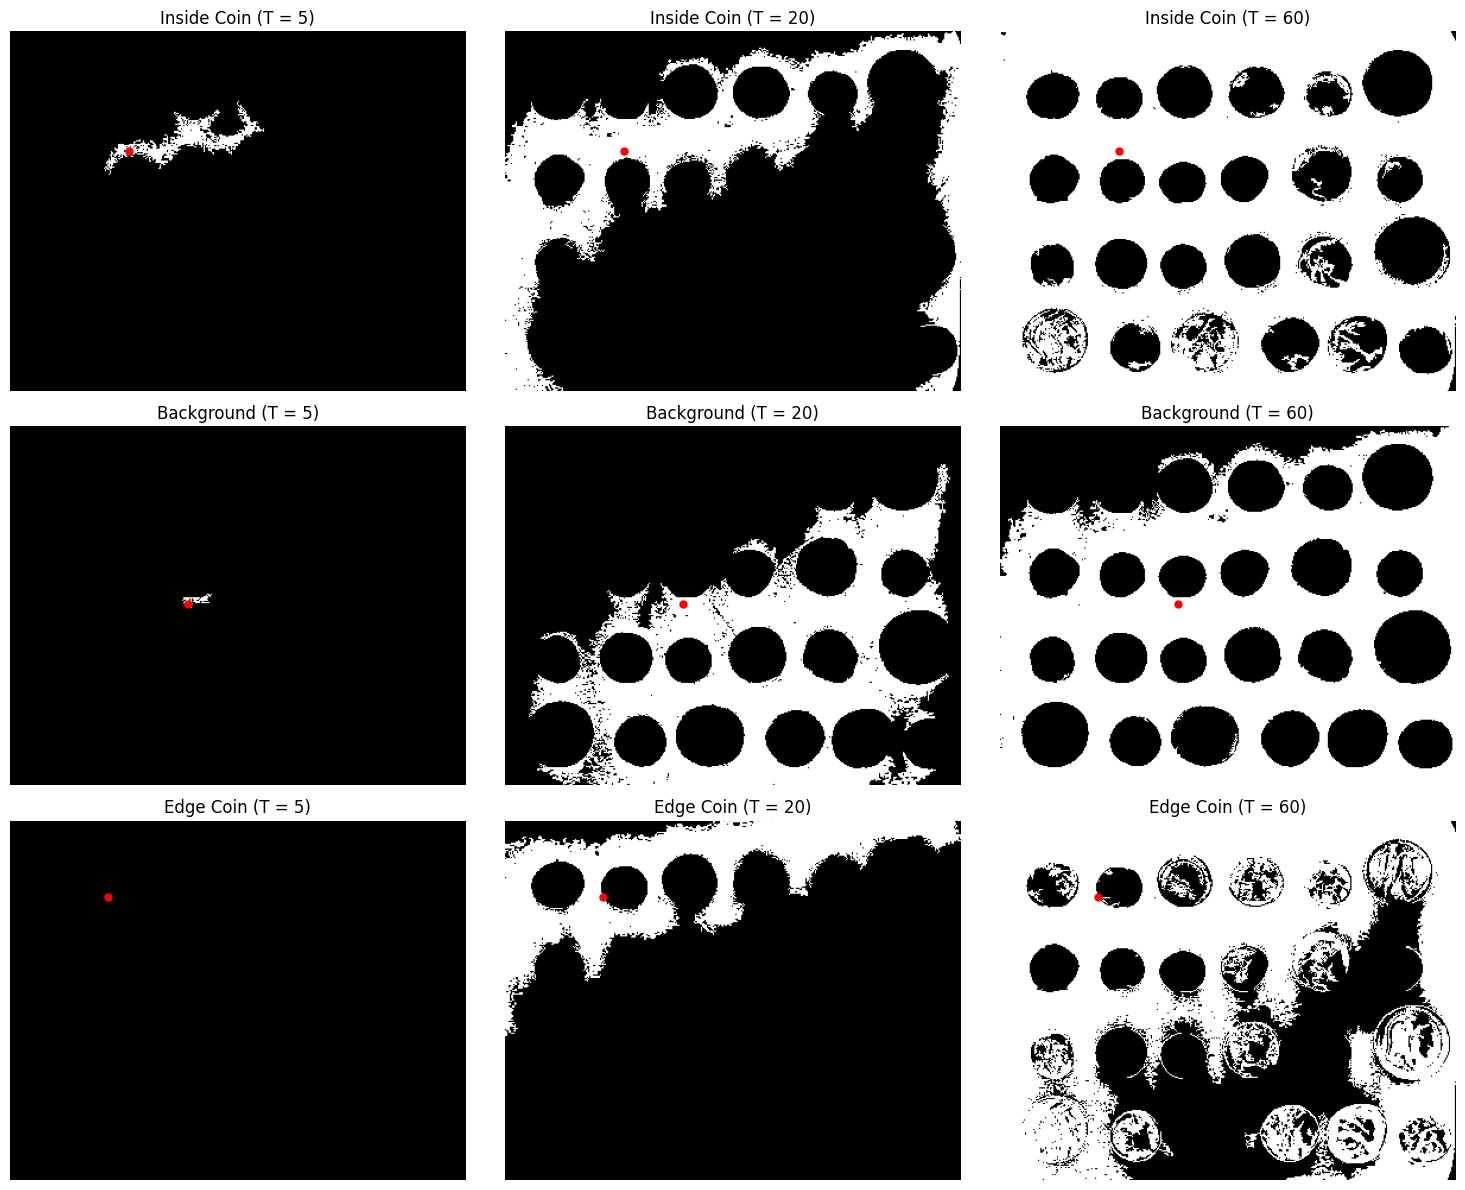

In [13]:
img_coins = data.coins()

seed_inside = (100, 100)
seed_bg = (150, 150)
seed_edge = (64, 82)

safety_seeds = [seed_inside, seed_bg, seed_edge]
seed_name = ['Inside Coin', 'Background', 'Edge Coin']

tolerances = [5, 20, 60]

fig, axes = plt.subplots(3, 3, figsize = (15, 12))

for i, (seed, name) in enumerate(zip(safety_seeds, seed_name)) :
  for j, T in enumerate(tolerances) :
    segmented = flood(img_coins, seed, tolerance = T)

    ax = axes[i, j]
    ax.imshow(segmented, cmap = 'gray')
    ax.set_title(f"{name} (T = {T})")

    ax.plot(seed[1], seed[0], 'ro', markersize = 5)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [14]:
gray = data.coins()
seed = (121, 63)

region = flood(
    gray,
    seed_point = seed,
    tolerance = 20,
    connectivity = 1
)

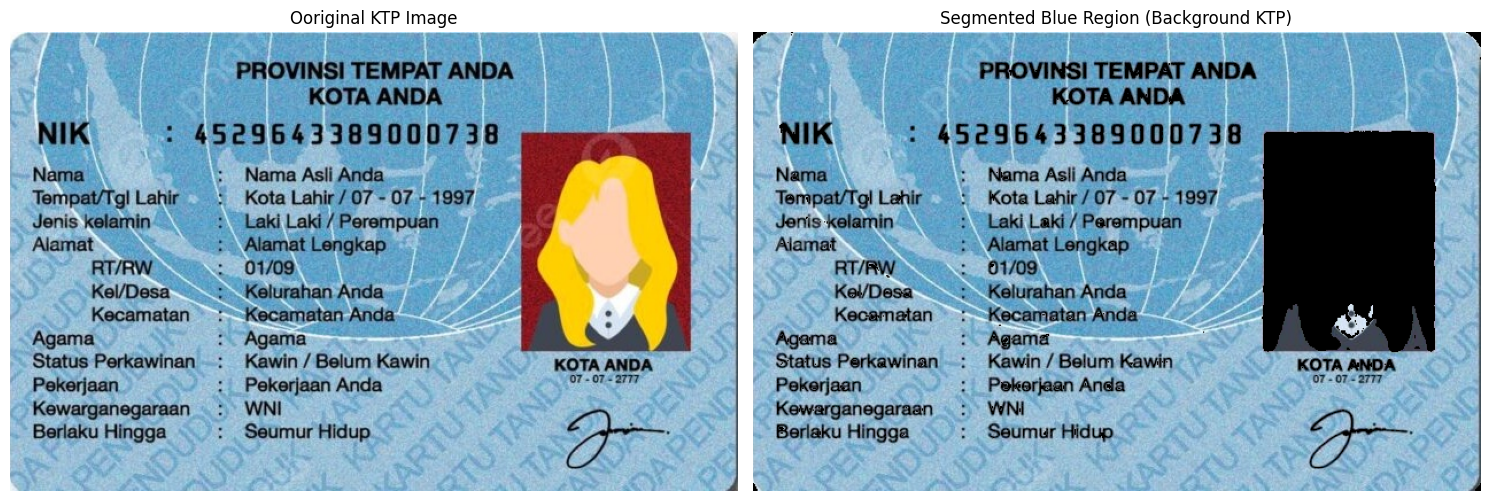

In [15]:
filepath_ktp = '/content/drive/MyDrive/PCVK/ktp_fulani.jpg'
img_ktp = cv.imread(filepath_ktp)
img_ktp_rgb = cv.cvtColor(img_ktp, cv.COLOR_BGR2RGB)

img_hsv = cv.cvtColor(img_ktp, cv.COLOR_BGR2HSV)
H, S, V = cv.split(img_hsv)

mask_biru = ((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

mask_uint = np.zeros_like(H, dtype = np.uint8)
mask_uint[mask_biru] = 255

blue_segmented = cv.bitwise_and(img_ktp_rgb, img_ktp_rgb, mask = mask_uint)

fig, axes = plt.subplots(1, 2, figsize = (15, 7))

axes[0].imshow(img_ktp_rgb)
axes[0].set_title('Ooriginal KTP Image')
axes[0].axis('off')

axes[1].imshow(blue_segmented)
axes[1].set_title('Segmented Blue Region (Background KTP)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [16]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


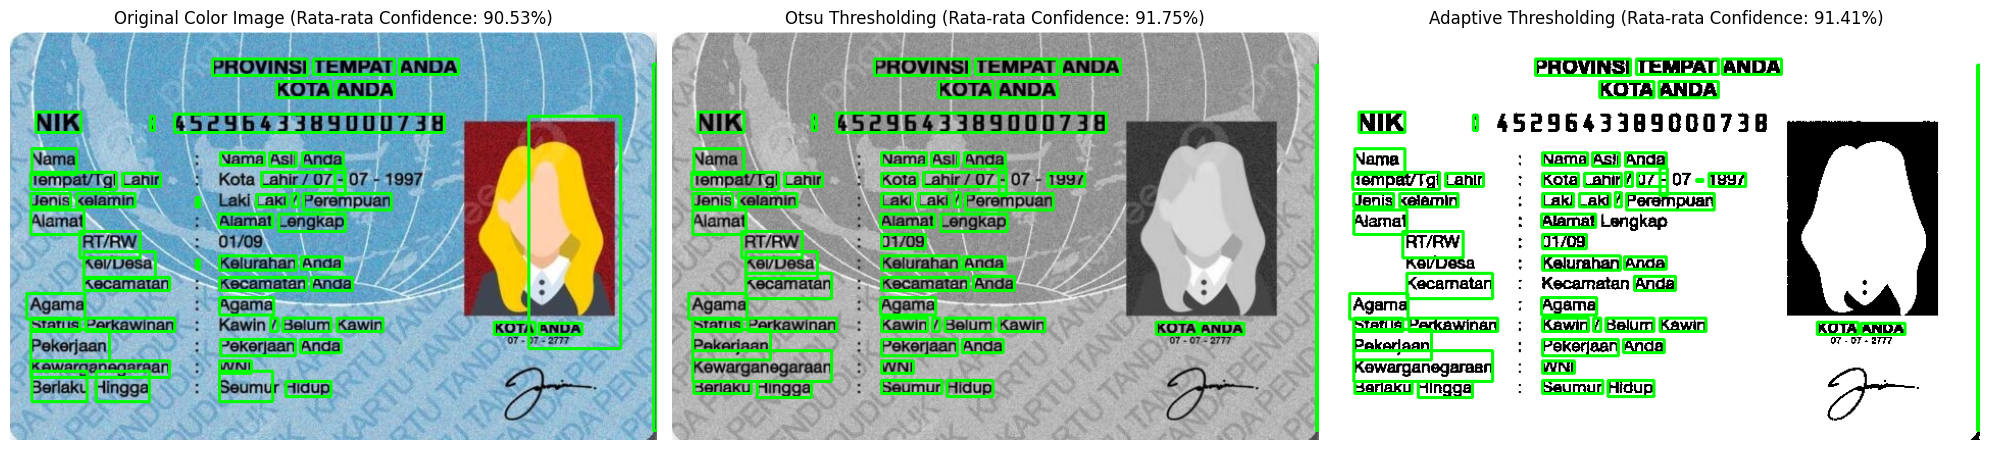

In [25]:
import pytesseract
from pytesseract import Output

img_gray = cv.cvtColor(img_ktp, cv.COLOR_BGR2GRAY)
_, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

img_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

images = [img_ktp_rgb, img_gray, img_otsu, img_adaptive]
titles = ['Original Color Image', 'Otsu Thresholding', 'Adaptive Thresholding']

ocr_results = {}

plt.figure(figsize = (20, 24))

for idx, (img_src, title) in enumerate(zip(images, titles)) :
  config_tess = '-l ind --psm 3'

  text_extracted = pytesseract.image_to_string(img_src, config = config_tess)
  ocr_results[title] = text_extracted
  if len(img_src.shape) == 2 :
    img_disp = cv.cvtColor(img_src, cv.COLOR_GRAY2RGB)
  else :
    img_disp = img_src.copy()

  d = pytesseract.image_to_data(img_src, config = config_tess, output_type = Output.DICT)
  n_boxes = len(d['text'])

  total_conf = []
  for i in range(n_boxes) :
    conf = int(d['conf'][i])
    if conf > 60 :
      (x, y, w, h_box) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
      # Gambar kotak hijau
      cv.rectangle(img_disp, (x, y), (x + w, y + h_box), (0, 255, 0), 2)
      total_conf.append(conf)

    avg_conf = np.mean(total_conf) if len(total_conf) > 0 else 0

    # Plot visualisasi
    plt.subplot(1, 3, idx + 1)
    plt.imshow(img_disp)
    plt.title(f"{title} (Rata-rata Confidence: {avg_conf:.2f}%)")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [26]:
# Menampilkan teks hasil pembacaan OCR untuk masing-masing citra
for title, text in ocr_results.items():
    print("="*50)
    print(f"HASIL OCR - {title.upper()}")
    print("="*50)
    print(text if text.strip() else "[Tidak ada teks yang terdeteksi]")
    print("\n")


HASIL OCR - ORIGINAL COLOR IMAGE
PROVINSI TEMPAT ANDA

KOTA ANDA

NIK : 4529643389000738
Nama : Nama Asli Anda,
Tempat/Tgl Lahir Kota Lahir/07 - 07 - 1997
Jenis kelamin : "aki Laki / Perempuan
Alamat 1. Alamat Lengkap

RT/RW 1. 01/09

Kel/Desa 1. Kelurahan Anda

Kecamatan — !— Kecamatan Anda,
Agama 1. Agama
Status Perkawinan -: Kawin / Belum Kawin KOTA ANDA
Pekerjaan 1! Pekerjaan Anda BAU Ja

Kewarganegaraan - : WNI
Berlaku Hingga 1. Seumur Hidup Daya




HASIL OCR - OTSU THRESHOLDING
PROVINSI TEMPAT ANDA

KOTA ANDA

NIK : 4529643389000738
Nama Nama Asli Anda,
Tempat/Tgl Lahir Kota Lahir/07 - 07.- 1997.
Jenis kelamin aki Laki / Perempuan
Alamat Alamat Lengkap

RT/RW 01/09

Kel/Desa Kelurahan Anda.

Kecamatan Kecamatan Anda
Agama Agama
Status Perkawinan Kawin / Belum Kawin
Pekerjaan Pekerjaan Anda
Kewarganegaraan WNI
Berlaku Hingga Seumur Hidup.

KOTA ANDA
OT 0122777

Dgn




HASIL OCR - ADAPTIVE THRESHOLDING
PROVINSI TEMPAT ANDA

KOTA ANDA

NIK : 4529643309000738
Nama Nama Asii Anda
Te

# LAPORAN EVALUASI DAN ANALISIS KINERJA OCR

## A. Tabel Perbandingan Hasil OCR (10 Kata Acuan)

| No. | Teks Sebenarnya | OCR Citra Berwarna | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | **PROVINSI** | PROVINSI | PROVINSI | *[Tidak Terdeteksi]* |
| 2 | **KOTA** | KOTA | KOTA | *[Tidak Terdeteksi]* |
| 3 | **4529643389000738** | 4529643389000738 | 4529643309000738 *(salah)* | *[Tidak Terdeteksi]* |
| 4 | **Lahir** | Lahir | *[Tidak Terdeteksi]* | *[Tidak Terdeteksi]* |
| 5 | **Perempuan** | Perempuan | Perempuan | *[Tidak Terdeteksi]* |
| 6 | **Alamat** | Alamat | Alamat | *[Tidak Terdeteksi]* |
| 7 | **01/09** | 01/09 | 01/09 | *[Tidak Terdeteksi]* |
| 8 | **Kecamatan** | Kecamatan | Kecamatan | *[Tidak Terdeteksi]* |
| 9 | **Kawin** | Kawin | Kawin | *[Tidak Terdeteksi]* |
| 10 | **WNI** | WNI | WNI | *[Tidak Terdeteksi]* |

## B. Ringkasan Hasil Pengujian OCR

| Citra Masukan OCR | Jumlah Item Terbaca Tepat (dari 10) | Tingkat Kecocokan (%) | Rata-rata Confidence (%) |
|---|---|---|---|
| **Citra Berwarna Asli** | 9 | **90%** | 90.53% |
| **Hasil Thresholding Otsu** | 8 | **80%** | 91.41% |
| **Hasil Adaptive Thresholding** | 0 | **0%** | 95.00% |

## C. Analisis dan Pembahasan

### 1. Citra masukan mana yang memberikan hasil OCR paling akurat? Jelaskan berdasarkan tabel.

**Jawaban:** Citra berwarna asli memberikan hasil pengenalan teks terbaik dengan tingkat kecocokan mencapai **90%**.

**Bukti:** Hal ini terlihat dari keberhasilan OCR dalam mengenali kata "Lahir" dan nomor NIK secara tepat. Sementara itu, pada hasil Otsu, kata "Lahir" tidak berhasil dikenali dan terdapat kesalahan pembacaan pada salah satu angka NIK, yaitu angka `8` yang terbaca sebagai `0`. Adapun hasil Adaptive Thresholding tidak berhasil mengenali teks acuan.

### 2. Sebutkan minimal dua bentuk kesalahan yang ditemukan selama proses pengenalan teks.

**Jawaban:**

1. **Kesalahan pengenalan angka pada metode Otsu:** Terdapat perubahan karakter angka `8` menjadi `0` pada bagian nomor NIK sehingga hasil pembacaannya tidak sesuai dengan teks asli.
2. **Teks tidak berhasil dikenali pada metode Adaptive:** Seluruh teks yang dijadikan acuan tidak dapat terdeteksi oleh Tesseract OCR. Kondisi ini diduga berkaitan dengan banyaknya noise yang muncul pada hasil thresholding sehingga bentuk karakter menjadi sulit dikenali.

### 3. Apakah penerapan segmentasi selalu dapat meningkatkan akurasi OCR? Jelaskan berdasarkan hasil pengujian.

**Jawaban:** Tidak. Berdasarkan hasil percobaan, penggunaan segmentasi tidak selalu memberikan peningkatan akurasi dalam proses OCR. Citra berwarna asli memperoleh tingkat kecocokan sebesar 90%, sedangkan metode Otsu hanya mencapai 80% dan Adaptive Thresholding memperoleh 0%.

Hasil tersebut menunjukkan bahwa proses segmentasi yang kurang optimal justru dapat mengurangi kualitas informasi pada citra. Misalnya, detail karakter dapat hilang, bentuk huruf mengalami perubahan, atau noise pada latar belakang bercampur dengan teks. Akibatnya, sistem OCR menjadi lebih sulit dalam mengenali karakter dengan benar.

### 4. Bagaimana pengaruh warna dan pola latar belakang terhadap kemampuan OCR dalam mengenali teks?

**Jawaban:** Warna dan pola latar belakang memiliki pengaruh terhadap keberhasilan pengenalan teks. Pada citra KTP, terdapat pola dekoratif berupa peta dunia serta gradasi warna biru yang dapat memengaruhi hasil proses thresholding.

Ketika citra diubah menjadi bentuk biner, pola latar belakang tersebut berpotensi menghasilkan noise berupa kumpulan piksel hitam dan putih. Jika noise berada terlalu dekat atau menyatu dengan karakter, bentuk asli huruf dapat berubah. Hal ini menyebabkan Tesseract OCR mengalami kesulitan dalam membedakan teks dari elemen latar belakang.

### 5. Apakah metode yang memiliki rata-rata confidence tertinggi juga menghasilkan tingkat kecocokan paling tinggi?

**Jawaban:** Tidak. Hasil pengujian menunjukkan bahwa Adaptive Thresholding memiliki rata-rata confidence tertinggi, yaitu 95.00%, tetapi tingkat kecocokan teksnya justru 0%.

Hal ini menunjukkan bahwa nilai confidence tidak selalu mencerminkan ketepatan hasil OCR terhadap teks sebenarnya. Confidence menggambarkan tingkat keyakinan sistem terhadap hasil pengenalan karakter yang berhasil dihasilkan, bukan persentase kesesuaian dengan teks acuan.

Dengan demikian, nilai confidence yang tinggi belum tentu menunjukkan bahwa hasil pengenalan sudah benar. Dalam kasus ini, nilai confidence perlu dianalisis bersama jumlah teks yang berhasil dikenali dan tingkat kecocokannya terhadap data sebenarnya.